In [2]:
#!pip install pyDOE
#!pip install tensorflow
#!pip install pydot
#!pip install graphviz

In [3]:
import os
import logging

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
logging.getLogger('tensorflow').setLevel(logging.ERROR)

In [5]:
import tensorflow as tf
import numpy as np
from pyDOE import lhs
import matplotlib.pyplot as plt
import pydot
import graphviz
import math
from matplotlib import cm
from matplotlib.ticker import LinearLocator
import time
import random
import os
import logging

In [6]:
# print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
tf.config.list_physical_devices('GPU')
from tensorflow.python.client import device_lib
# print(device_lib.list_local_devices())

In [7]:
# Initial condition
x0, y0 = np.log(0.9), np.log(0.9)


# Boundaries of the computational domain
t0, tfinal = 0.0, 12

In [8]:
decimal_p = 4

In [9]:
a = 2/3
b = 4/3
c = 1
d = 1

In [10]:
v0 = (c * (math.exp(x0))) - (d * x0) + (b * math.exp(y0)) - (a * y0)

print(v0)

2.275600859429711


In [11]:
with open('../baseline/parameters/a=2,3_b=4,3_c=1_d=1_t0=0_tfinal=12_h=0.001.npy', 'rb') as f:

    points = np.load(f)

tpoints = points[0]
tpoints = np.round(tpoints, decimal_p)
xpoints = points[1]
ypoints = points[2]

In [12]:
# Define the normalization layer
class Normalize(tf.keras.layers.Layer):
  def __init__(self, xmin, xmax, name=None, **kwargs):
    super(Normalize, self).__init__(name=name)
    self.xmin = xmin
    self.xmax = xmax
    super(Normalize, self).__init__(**kwargs)

  def call(self, inputs):
    return 2.0*(inputs-self.xmin)/(self.xmax-self.xmin)-1.0

  def get_config(self):
    config = super(Normalize, self).get_config()
    config.update({'xmin': self.xmin, 'xmax': self.xmax})
    return config

In [13]:
# Define the network
def build_model(nr_units=40, nr_layers=4, summary=False):

  inp = b = tf.keras.layers.Input(shape=(1,))
  b = Normalize(t0, tfinal)(b)

  for i in range(nr_layers):
    b = tf.keras.layers.Dense(nr_units, activation='tanh')(b)
  outx = tf.keras.layers.Dense(1, activation='linear')(b)
  outy = tf.keras.layers.Dense(1, activation='linear')(b)

  model = tf.keras.models.Model(inp, [outx, outy])
  
  if summary:
    model.summary()

  return model

In [14]:
model = build_model(summary = True)

I0000 00:00:1793071990.559515 2674420 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalize_1         │ (None, 1)         │          0 │ input_layer[0][0] │
│ (Normalize)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 40)        │         80 │ normalize_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 40)        │      1,640 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 40)        │      1,640 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 40)        │      1,640 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         41 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         41 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,082 (19.85 KB)

 Trainable params: 5,082 (19.85 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# tf.keras.utils.plot_model(model)

In [16]:
# Define the collocation points over the domain [t_0, t_1]
def defineCollocationPoints(t_bdry, N_pde=100):

    # Sample points where to evaluate the PDE
  ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N_pde)

  return ode_points

In [17]:
# Define the collocation points
de_points = defineCollocationPoints([t0, tfinal], 100)

Text(0.5, 1.0, 'Collocation points')

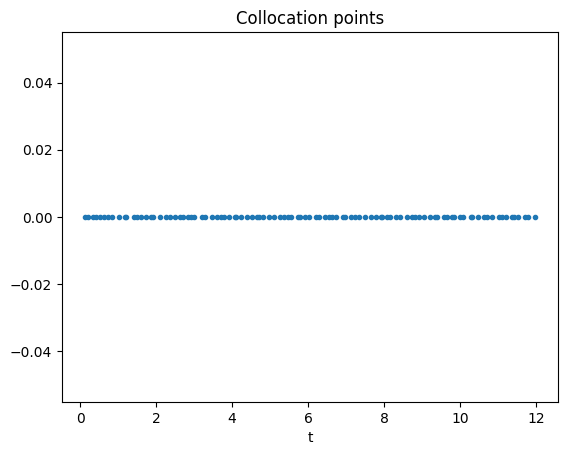

In [18]:
plt.plot(de_points[:,0], 0*de_points[:,0],'.')
plt.xlabel('t')
plt.title('Collocation points')

In [19]:
# The main training function
@tf.function
def train_network(odes, inits, model, gamma, epsilon, phi):

    # DE collocation points
    t_de = odes[:,:1]

    # Initial value points
    t_init, x_init, y_init = inits[:1], inits[1:2], inits[2:]

    # Outer gradient for tuning network parameters
    with tf.GradientTape() as tape:

      # Inner gradient for derivatives of u wrt x and t
      with tf.GradientTape(persistent=True) as tape2:
        tape2.watch(t_de)
        [x, y] = model(t_de, training=True)
        
        
        V = (c * (tf.math.exp(model(t_de, training=True)[0]))) - (d * model(t_de, training=True)[0]) + (b * tf.math.exp(model(t_de, training=True)[1])) - (a * model(t_de, training=True)[1])

      # Derivative of the neural network solution
      xt = tape2.gradient(x, t_de)
      yt = tape2.gradient(y, t_de)
      Vt = tape2.gradient(V, t_de)
        

      # Define the differential equation loss  
      eqn1 = xt - a + b*(tf.math.exp(y))
      eqn2 = yt - c*(tf.math.exp(x)) + d
      DEloss = tf.reduce_mean(tf.square(eqn1) + tf.square(eqn2))
                         
      # Define the initial value loss
      [x_init_pred, y_init_pred] = model(t_init, training=True)
      IVloss = tf.reduce_mean(tf.square(x_init_pred - x_init) + tf.square(y_init_pred - y_init))
    
    
      #Implicit integration loss
      v = (c * (tf.math.exp(x))) - (d * x) + (b * tf.math.exp(y)) - (a * y)
      #vt = (c * (tf.math.exp(x)) * xt) - (d * xt) + (b * tf.math.exp(y) * yt) - (a * yt)
             
      Vloss = tf.math.reduce_mean(tf.square(tf.boolean_mask(v, tf.math.is_finite(v))) - v0)
      Vtloss = tf.reduce_mean(tf.math.square(Vt))
    
    
      # Composite loss function
      loss = 12*DEloss + gamma*IVloss + epsilon*Vloss + phi*Vtloss

    grads = tape.gradient(loss, model.trainable_variables)
    
    return DEloss, IVloss, Vloss, Vtloss, grads

In [20]:
def PINNtrain(de_points, x0, y0, epochs, gamma_val, epsilon_val, phi_val):

  # Total number of collocation points
  N_de = len(de_points)

  # Batch size
  bs_de = N_de//10

  # Weight factors
  gamma = gamma_val
  epsilon = epsilon_val
  phi = phi_val

  # Learning rate
  lr_model = 1e-3

  # Initial value
  t_init = np.array([t0]).astype(np.float32)
  x_init = np.array([x0]).astype(np.float32)
  y_init = np.array([y0]).astype(np.float32)

  epoch_loss = np.zeros(epochs)
  nr_batches = 0

  # Generate the tf.Dataset for the initial collocation points
  inits = np.column_stack([t_init, x_init, y_init])
  ds_init = tf.data.Dataset.from_tensor_slices(inits)
  ds_init = ds_init.cache()


  # Generate the tf.Dataset for the differential equations points
  ds_ode = tf.data.Dataset.from_tensor_slices(de_points.astype(np.float32))
  ds_ode = ds_ode.cache().shuffle(N_de).batch(bs_de)

  # Generate entire dataset
  ds = tf.data.Dataset.zip((ds_ode, ds_init))

  ds = ds.prefetch(tf.data.experimental.AUTOTUNE)

  # Generate the model
  opt = tf.keras.optimizers.Adam(lr_model)
  model = build_model() 

  # Main training loop
  for i in range(epochs):

    # Training for that epoch
    for (des, inits) in ds:

      # Train the network
      DEloss, IVloss, Vloss, Vtloss, grads = train_network(des, inits, model, gamma, epsilon, phi)

      # Gradient step
      opt.apply_gradients(zip(grads, model.trainable_variables))
      
      epoch_loss[i] += DEloss + gamma*IVloss + epsilon*Vloss + phi*Vtloss
      nr_batches = nr_batches + 1

    # Get total epoch loss
    epoch_loss[i] = epoch_loss[i]/nr_batches
    nr_batches = 0

    
    if (np.mod(i, 500)==0):
      print("DE loss, IV loss, Vloss, Vtloss in {}th epoch: {: 6.4f}, {: 6.4f}, {: 6.4f}, {: 6.8f}.".format(i, DEloss, IVloss, Vloss, Vtloss))

  return epoch_loss, model

In [21]:
error_dict = {}

def train_plot(epochs, gamma, epsilon, phi) :


    loss, model = PINNtrain(de_points, x0, y0, epochs, gamma, epsilon, phi)
    
    # Grid where to evaluate the model
    step_size = 0.005
    t = np.arange(t0, tfinal, step_size)
    t = np.round(t, decimal_p)
    
    plt.figure(1)
    plt.plot(loss)

    # Model prediction
    [x, y] = model(t)
    
    x = tf.math.exp(x)
    y = tf.math.exp(y)
    
    # Plot the solution
    # print(len(x))
    
    plt.figure(2)
    plt.plot(x, y, label = "e = " + str(epochs) + ", gamma = " + str(gamma) + ", epsilon = " + str(epsilon)  + ", phi = " + str(phi))
    plt.legend(loc='best')
    plt.plot(xpoints, ypoints, color = 'black')
    
    error = calc_err(t, x, y)    
    
    if phi in error_dict.keys() :
        
        error_dict[phi] = error_dict[phi] + error
        
    else :
        
        error_dict[phi] = error
        
        
    plt.figure(3)
    
    plt.scatter(phi, error)
    
    plt.figure(4)
    plt.plot(tpoints, xpoints, color = 'black')
    plt.plot(t, x)
    
    plt.figure(5)
    plt.plot(tpoints, ypoints, color = 'black')
    plt.plot(t, y)
    


In [22]:
def calc_err(t_preds, x_preds, y_preds) :
    
    error = 0
    
    for i in range(len(t_preds)) :
        
        t_i = np.where(tpoints == t_preds[i])
        
        err = np.abs(x_preds[i] - xpoints[t_i])  + np.abs(y_preds[i] - ypoints[t_i])
        
        error = error + err
        
    return error

In [24]:
# start = time.time()

DE loss, IV loss, Vloss, Vtloss in 0th epoch:  0.4504,  0.2104,  3.2004,  0.00309799.
DE loss, IV loss, Vloss, Vtloss in 500th epoch:  0.0045,  0.0440,  2.2950,  0.00005587.
DE loss, IV loss, Vloss, Vtloss in 1000th epoch:  0.0023,  0.0199,  2.3288,  0.00004587.
DE loss, IV loss, Vloss, Vtloss in 1500th epoch:  0.0047,  0.0104,  2.3937,  0.00030420.
DE loss, IV loss, Vloss, Vtloss in 2000th epoch:  0.0029,  0.0009,  2.3189,  0.00009702.
DE loss, IV loss, Vloss, Vtloss in 2500th epoch:  0.0020,  0.0072,  2.3772,  0.00007117.
DE loss, IV loss, Vloss, Vtloss in 3000th epoch:  0.0018,  0.0065,  2.3095,  0.00003982.
DE loss, IV loss, Vloss, Vtloss in 3500th epoch:  0.0029,  0.0019,  2.4216,  0.00024526.
DE loss, IV loss, Vloss, Vtloss in 4000th epoch:  0.0018,  0.0055,  2.3617,  0.00008250.
DE loss, IV loss, Vloss, Vtloss in 4500th epoch:  0.0012,  0.0034,  2.3901,  0.00004482.
DE loss, IV loss, Vloss, Vtloss in 0th epoch:  0.3788,  0.0396,  2.9508,  0.00048694.
DE loss, IV loss, Vloss, Vtl

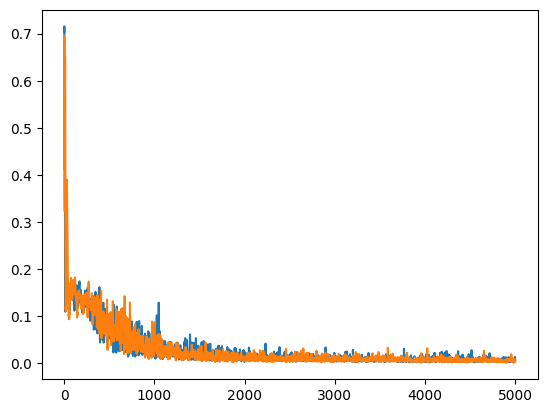

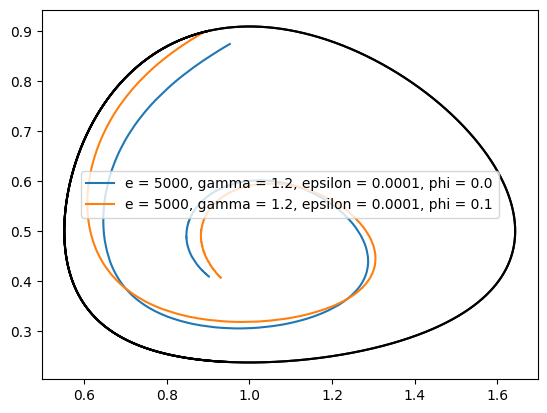

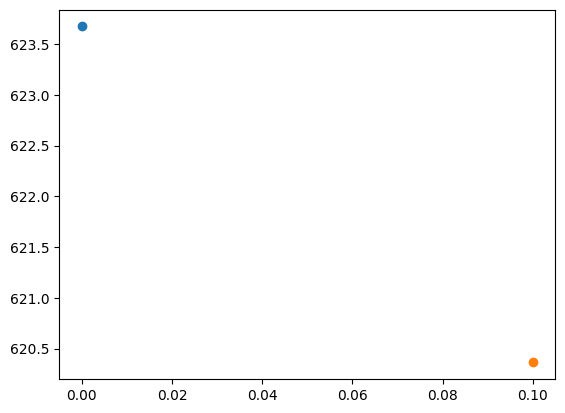

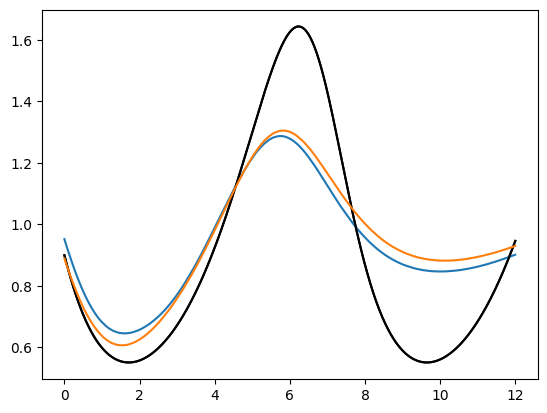

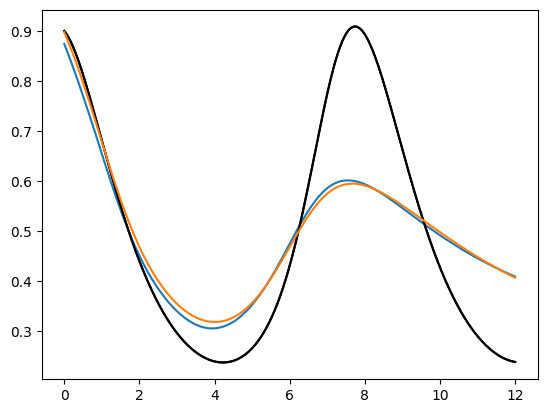

In [23]:
epochs = 5000
    
train_plot(epochs, 1.2, 0.0001, 0.0)
train_plot(epochs, 1.2, 0.0001, 0.1)
# train_plot(epochs, 1.2, 0.0001, 0.01)
# train_plot(epochs, 1.2, 0.0001, 0.001)

In [25]:
print(error_dict)

{0.0: array([623.67413], dtype=float32), 0.1: array([620.3625], dtype=float32)}


In [1]:
# end = time.time()

# print((end-start)/60)